In [7]:
import pandas as pd
import numpy as np
from pathlib import Path

# Folder z plikami
folder = Path(r"D:\MOdel_wewnetrzny\test_pz")

# Pliki Excel
plik_paid = folder / "trojkat_7K_paid.xlsx"
plik_incurred = folder / "trojkat_Incurred_7K.xlsx"

# Wczytanie trójkątów skumulowanych
paid_df = pd.read_excel(
    plik_paid,
    sheet_name="Trojkat_skumulowany",
    index_col=0
)

import numpy as np
import pandas as pd

incurred_incremental_df = pd.read_excel(
    plik_incurred,
    sheet_name="Incurred przyrostowy",
    index_col=0
).astype(float)

n, m = incurred_incremental_df.shape

mask = (
    np.arange(m)[None, :]
    < n - np.arange(n)[:, None]
)

data = incurred_incremental_df.to_numpy(copy=True)

data[mask & np.isnan(data)] = 0.0
data[~mask] = np.nan

incurred_incremental_df.iloc[:, :] = data

incurred_df = incurred_incremental_df.cumsum(axis=1)

#display(incurred_df)
 
# Konwersja do macierzy NumPy
paid = paid_df.to_numpy(dtype=np.float64)
incurred = incurred_df.to_numpy(dtype=np.float64)

# Kontrola wymiarów
print("Paid:", paid.shape)
print("Incurred:", incurred.shape)

# Wyświetlenie danych
#display(paid_df)
#display(incurred_df)

Paid: (22, 22)
Incurred: (22, 22)


In [8]:
import numpy as np

weights_inc = np.array([
    [1]*21,
    [1]*20 + [0],
    [1]*19 + [0]*2,
    [1]*18 + [0]*3,
    [1]*17 + [0]*4,
    [1]*16 + [0]*5,
    [1]*15 + [0]*6,
    [1]*14 + [0]*7,
    [1]*13 + [0]*8,
    [1]*12 + [0]*9,
    [1]*11 + [0]*10,
    [1]*10 + [0]*11,
    [1]*9  + [0]*12,
    [1]*8  + [0]*13,
    [1]*7  + [0]*14,
    [1]*6  + [0]*15,
    [1]*5  + [0]*16,
    [1]*4  + [0]*17,
    [1]*3  + [0]*18,
    [0]*21,
    [1]    + [0]*20
], dtype=np.int64)



In [9]:
import numpy as np

inflacja = np.array([
    [2003,  0.008],
    [2004,  0.035],
    [2005,  0.021],
    [2006,  0.010],
    [2007,  0.025],
    [2008,  0.042],
    [2009,  0.035],
    [2010,  0.026],
    [2011,  0.043],
    [2012,  0.037],
    [2013,  0.009],
    [2014,  0.000],
    [2015, -0.009],
    [2016, -0.006],
    [2017,  0.020],
    [2018,  0.016],
    [2019,  0.023],
    [2020,  0.034],
    [2021,  0.051],
    [2022,  0.144],
    [2023,  0.114],
    [2024,  0.037],
    [2025,  0.056],
    [2026,  0.027],
    [2027,  0.025],
    [2028,  0.025],
    [2029,  0.025],
    [2030,  0.025],
    [2031,  0.025],
    [2032,  0.025],
    [2033,  0.025],
    [2034,  0.025],
    [2035,  0.025],
    [2036,  0.025],
    [2037,  0.025],
    [2038,  0.025],
    [2039,  0.025],
    [2040,  0.025],
    [2041,  0.025],
    [2042,  0.025],
    [2043,  0.025],
    [2044,  0.025],
    [2045,  0.025],
    [2046,  0.025],
    [2047,  0.025],
    [2048,  0.025],
    [2049,  0.025],
    [2050,  0.025],
    [2051,  0.025],
    [2052,  0.025],
    [2053,  0.025],
    [2054,  0.025],
    [2055,  0.025]
], dtype=np.float64)

In [10]:
### wyznaczam macierze

In [11]:
import numpy as np

# 1. Trójkąty skumulowane
C = paid_df.to_numpy(dtype=np.float64)
I = incurred_df.to_numpy(dtype=np.float64)

# 2. Wspólne obserwacje
mask = np.isfinite(C) & np.isfinite(I)

C = np.where(mask, C, np.nan)
I = np.where(mask, I, np.nan)

# 3. Macierz rezerw
R = I - C

# 4. Przyrosty Incurred
X_I = np.full_like(I, np.nan)
X_I[:, 0] = I[:, 0]
X_I[:, 1:] = I[:, 1:] - I[:, :-1]

# 5. Pozostałe macierze
X_R = R.copy()
E_I = I.copy()
E_R = R.copy()

# 6. Indywidualne współczynniki Incurred
X_next = X_I[:, 1:]
E_current = E_I[:, :-1]

L_I = np.full_like(X_next, np.nan)

valid = np.isfinite(X_next) & np.isfinite(E_current)

positive = valid & (E_current > 0)
zero = valid & (E_current == 0)

L_I[positive] = X_next[positive] / E_current[positive]
L_I[zero] = 0.0

 

In [12]:
import numpy as np

# Konwersja do NumPy
X_R_np = np.asarray(X_R, dtype=np.float64)
E_R_np = np.asarray(E_R, dtype=np.float64)

# Licznik: X^R_(i,j+1)
X_next_R = X_R_np[:, 1:]

# Mianownik: E^R_(i,j)
E_current_R = E_R_np[:, :-1]

# Macierz współczynników rozwoju rezerw
L_R = np.full_like(X_next_R, np.nan)

# Dostępne obserwacje
valid = np.isfinite(X_next_R) & np.isfinite(E_current_R)

# Dodatni nośnik ryzyka
positive = valid & (E_current_R > 0)

L_R[positive] = X_next_R[positive] / E_current_R[positive]

# Zerowy nośnik ryzyka
zero = valid & (E_current_R == 0)

L_R[zero] = 0.0
 

In [18]:

# 1. Rezerwy
R = np.round(I - C, 2)

# 2. Ekspozycje
E_R = R.copy()
X_R = R.copy()

# 3. Indywidualne współczynniki
L_R = np.full((R.shape[0], R.shape[1] - 1), np.nan)

E_current_R = E_R[:, :-1]
X_next_R = X_R[:, 1:]

valid = np.isfinite(E_current_R) & np.isfinite(X_next_R)

positive = valid & (E_current_R > 0)
zero = valid & (E_current_R == 0)

L_R[positive] = X_next_R[positive] / E_current_R[positive]
L_R[zero] = 0.0


In [47]:
import numpy as np

# Kopie macierzy historycznych
I_hat = I.copy()
R_hat = R.copy()
C_hat = C.copy()

# Macierz przyszłych płatności przyrostowych
X_paid_hat = np.full_like(C, np.nan)

a = I.shape[0]

# Prognozowanie dolnego trójkąta
for i in range(1, a):

    # Ostatnia obserwowana kolumna
    last = a - i - 1

    for j in range(last + 1, a):

        # Przyrost Incurred
        x_i = I_hat[i, j-1] * h[j-1]

        # Nowa rezerwa
        r_new = R_hat[i, j-1] * g[j-1]

        # Oczekiwane Incurred
        I_hat[i, j] = I_hat[i, j-1] + x_i

        # Oczekiwana rezerwa
        R_hat[i, j] = r_new

        # Przyszła płatność przyrostowa
        X_paid_hat[i, j] = (
            x_i - (r_new - R_hat[i, j-1])
        )

        # Skumulowane Paid
        C_hat[i, j] = C_hat[i, j-1] + X_paid_hat[i, j]

print("Wymiar X_paid_hat:", X_paid_hat.shape)

print(
    "Suma przyszłych płatności bez inflacji:",
    np.nansum(X_paid_hat)
)

Wymiar X_paid_hat: (22, 22)
Suma przyszłych płatności bez inflacji: 648670738.6762593


In [13]:
import numpy as np
import pandas as pd

j = 13
k = j - 1

E = np.asarray(E_R, dtype=float)
L = np.asarray(L_R, dtype=float)
W = np.asarray(weights_inc, dtype=float)

a = E.shape[0]
n = a - j

kontrola = pd.DataFrame({
    "EVENT_YEAR": incurred_df.index[:n],
    "Rezerwa_R_j": E[:n, k],
    "Rezerwa_R_j_plus_1": E[:n, k + 1],
    "L_R": L[:n, k],
    "Waga": W[:n, k]
})

display(kontrola)

print("Liczba wag = 1:",
      np.sum(W[:n, k] == 1))

print("Liczba dodatnich rezerw:",
      np.sum((E[:n, k] > 0) & (W[:n, k] == 1)))

print("Suma ważonych rezerw:",
      np.sum(E[:n, k][W[:n, k] == 1]))

,EVENT_YEAR,Rezerwa_R_j,Rezerwa_R_j_plus_1,L_R,Waga
0,2003,0.000000e+00,-1.490116e-08,0.000000,1.0
1,2004,-1.490116e-08,-1.490116e-08,NaN,1.0
2,2005,-7.450581e-09,0.000000e+00,NaN,1.0
3,2006,-1.490116e-08,-1.490116e-08,NaN,1.0
4,2007,-5.960464e-08,-5.960464e-08,NaN,1.0
5,2008,0.000000e+00,0.000000e+00,0.000000,1.0
6,2009,9.223902e+04,7.303215e+04,0.791771,1.0
7,2010,1.192093e-07,1.192093e-07,1.000000,1.0
8,2011,0.000000e+00,0.000000e+00,0.000000,1.0


Liczba wag = 1: 9
Liczba dodatnich rezerw: 2
Suma ważonych rezerw: 92239.02000000328


In [14]:

import numpy as np


def calculate_parameters_inc(
    L_I,
    E_I,
    weights_inc,
    weights_var_inc=None
):
    """
    Estymacja parametrów średniej i wariancji
    modelu Paid-Incurred dla szkód zgłoszonych.

    Zwraca
    -------
    h : ndarray (a-1,)
        Współczynniki rozwoju Incurred.

    theta2_I : ndarray (a-1,)
        Parametry wariancji Incurred.
    """

    L_I = np.asarray(L_I, dtype=np.float64)
    E_I = np.asarray(E_I, dtype=np.float64)
    weights_inc = np.asarray(weights_inc, dtype=np.float64)

    if weights_var_inc is None:
        weights_var_inc = weights_inc.copy()
    else:
        weights_var_inc = np.asarray(
            weights_var_inc, dtype=np.float64
        )

    a = E_I.shape[0]

    # Kontrola wymiarów
    if E_I.shape != (a, a):
        raise ValueError("E_I musi mieć wymiar (a, a).")

    if L_I.shape != (a, a - 1):
        raise ValueError("L_I musi mieć wymiar (a, a-1).")

    for name, w in [
        ("weights_inc", weights_inc),
        ("weights_var_inc", weights_var_inc)
    ]:
        if w.shape != (a - 1, a - 1):
            raise ValueError(f"Nieprawidłowy wymiar {name}.")

        if not np.all(np.isin(w, [0, 1])):
            raise ValueError(f"{name} musi zawierać 0 lub 1.")

    h = np.full(a - 1, np.nan)
    theta2_I = np.full(a - 1, np.nan)

    # =========================================
    # 1. ESTYMACJA ŚREDNIEJ h_j
    # =========================================

    for j in range(a - 1):

        n = a - j - 1

        E_j = E_I[:n, j]
        L_j = L_I[:n, j]
        w_j = weights_inc[:n, j]

        selected = w_j == 1

        E_sel = E_j[selected]
        L_sel = L_j[selected]

        if not (
            np.all(np.isfinite(E_sel))
            and np.all(np.isfinite(L_sel))
        ):
            raise ValueError(
                f"Okres j={j+1}: niepoprawne dane."
            )

        denominator = np.sum(E_sel)
        numerator = np.sum(E_sel * L_sel)

        if denominator <= 0:
            raise ValueError(
                f"Okres j={j+1}: mianownik <= 0. "
                "Wymagana ekstrapolacja."
            )

        h[j] = numerator / denominator

    # =========================================
    # 2. ESTYMACJA WARIANCJI
    # =========================================

    for j in range(a - 2):

        n = a - j - 1

        E_j = E_I[:n, j]
        L_j = L_I[:n, j]
        w_j = weights_var_inc[:n, j]

        selected = w_j == 1
        N = np.sum(selected)

        if N <= 1:
            raise ValueError(
                f"Okres j={j+1}: liczba obserwacji <= 1. "
                "Wymagana ekstrapolacja."
            )

        E_sel = E_j[selected]
        L_sel = L_j[selected]

        if not (
            np.all(np.isfinite(E_sel))
            and np.all(np.isfinite(L_sel))
        ):
            raise ValueError(
                f"Okres j={j+1}: niepoprawne dane."
            )

        if np.any(E_sel < 0):
            raise ValueError(
                f"Okres j={j+1}: ujemny nośnik ryzyka."
            )

        denominator = np.sum(E_sel)

        if denominator <= 0:
            raise ValueError(
                f"Okres j={j+1}: niedodatni mianownik."
            )

        # Średnia wyznaczona z wag wariancyjnych
        h_r = np.sum(E_sel * L_sel) / denominator

        theta2_I[j] = (
            np.sum(E_sel * (L_sel - h_r)**2)
            / (N - 1)
        )

    # =========================================
    # 3. EKSTRAPOLACJA OSTATNIEJ WARIANCJI
    # =========================================

    if not np.all(np.isfinite(theta2_I[-3:-1])):
        raise ValueError(
            "Brak dwóch poprzednich parametrów wariancji."
        )

    if theta2_I[-3] <= 0:
        raise ValueError(
            "Nie można zastosować ekstrapolacji: "
            "theta2_I[-3] <= 0."
        )

    theta2_I[-1] = min(
        theta2_I[-2]**2 / theta2_I[-3],
        theta2_I[-3],
        theta2_I[-2]
    )

    return h, theta2_I


In [16]:

import numpy as np


def calculate_parameters_R(
    L_R,
    E_R,
    weights_R,
    j_star=15,
    weights_var_R=None
):
    """
    Estymacja parametrów średniej i wariancji
    modelu Paid-Incurred dla rezerw.

    Zwraca
    -------
    g : ndarray (a-1,)
        Współczynniki rozwoju rezerw.

    theta2_R : ndarray (a-1,)
        Parametry wariancji rezerw.
    """

    L_R = np.asarray(L_R, dtype=np.float64)
    E_R = np.asarray(E_R, dtype=np.float64)
    weights_R = np.asarray(weights_R, dtype=np.float64)

    if weights_var_R is None:
        weights_var_R = weights_R.copy()
    else:
        weights_var_R = np.asarray(
            weights_var_R, dtype=np.float64
        )

    a = E_R.shape[0]

    # Kontrola wymiarów
    if E_R.shape != (a, a):
        raise ValueError("E_R musi mieć wymiar (a, a).")

    if L_R.shape != (a, a - 1):
        raise ValueError("L_R musi mieć wymiar (a, a-1).")

    for name, w in [
        ("weights_R", weights_R),
        ("weights_var_R", weights_var_R)
    ]:
        if w.shape != (a - 1, a - 1):
            raise ValueError(f"Nieprawidłowy wymiar {name}.")

        if not np.all(np.isin(w, [0, 1])):
            raise ValueError(f"{name} musi zawierać 0 lub 1.")

    if not isinstance(j_star, (int, np.integer)):
        raise ValueError("j_star musi być liczbą całkowitą.")

    if not 1 <= j_star <= a - 1:
        raise ValueError("Nieprawidłowe j_star.")

    g = np.zeros(a - 1, dtype=np.float64)
    theta2_R = np.zeros(a - 1, dtype=np.float64)

    # =========================================
    # 1. ESTYMACJA ŚREDNIEJ g_j
    # =========================================

    for j in range(j_star - 1):

        n = a - j - 1

        E_j = E_R[:n, j]
        L_j = L_R[:n, j]
        w_j = weights_R[:n, j]

        selected = w_j == 1

        E_sel = E_j[selected]
        L_sel = L_j[selected]

        if not (
            np.all(np.isfinite(E_sel))
            and np.all(np.isfinite(L_sel))
        ):
            raise ValueError(
                f"Okres j={j+1}: niepoprawne dane."
            )

        denominator = np.sum(E_sel)
        numerator = np.sum(E_sel * L_sel)

        if denominator <= 0:
            raise ValueError(
                f"Okres j={j+1}: niedodatni mianownik."
            )

        g[j] = numerator / denominator

        if g[j] <= 0:
            raise ValueError(
                f"Okres j={j+1}: g_j={g[j]}. "
                "Wymagane g_j > 0."
            )

    # =========================================
    # 2. ESTYMACJA WARIANCJI
    # =========================================

    for j in range(min(j_star - 1, a - 2)):

        n = a - j - 1

        E_j = E_R[:n, j]
        L_j = L_R[:n, j]
        w_j = weights_var_R[:n, j]

        selected = w_j == 1
        N = np.sum(selected)

        if N <= 1:
            raise ValueError(
                f"Okres j={j+1}: liczba obserwacji <= 1. "
                "Wymagana ekstrapolacja."
            )

        E_sel = E_j[selected]
        L_sel = L_j[selected]

        if not (
            np.all(np.isfinite(E_sel))
            and np.all(np.isfinite(L_sel))
        ):
            raise ValueError(
                f"Okres j={j+1}: niepoprawne dane."
            )

        denominator = np.sum(E_sel)

        if denominator <= 0:
            raise ValueError(
                f"Okres j={j+1}: niedodatni mianownik."
            )

        # Średnia wyznaczona z wag wariancyjnych
        g_r = np.sum(E_sel * L_sel) / denominator

        theta2_R[j] = (
            np.sum(E_sel * (L_sel - g_r)**2)
            / (N - 1)
        )

    # =========================================
    # 3. ZEROWANIE OD j_star
    # =========================================

    g[j_star - 1:] = 0.0
    theta2_R[j_star - 1:] = 0.0

    return g, theta2_R


In [41]:

import numpy as np
from scipy.stats import spearmanr, rankdata


def calculate_lambda(
    X_I, X_R, E_I, E_R,
    h, g, theta2_I, theta2_R,
    weights_lambda,
    j_star
):
    """
    Estymacja korelacji Spearmana w modelu Paid-Incurred.

    Dla E_R = 0 przyjmujemy r_R = 0.
    Rangi wiązane uwzględniamy metodą średnich rang.

    Zwraca
    -------
    lambda_S : ndarray (a-1,)
        Korelacje Spearmana.

    r_I : ndarray (a, a-1)
        Standaryzowane reszty Incurred.

    r_R : ndarray (a, a-1)
        Standaryzowane reszty rezerw.

    diagnostics : list
        (okres, liczba_obserwacji, status)
    """

    X_I = np.asarray(X_I, dtype=np.float64)
    X_R = np.asarray(X_R, dtype=np.float64)
    E_I = np.asarray(E_I, dtype=np.float64)
    E_R = np.asarray(E_R, dtype=np.float64)

    h = np.asarray(h, dtype=np.float64)
    g = np.asarray(g, dtype=np.float64)

    theta2_I = np.asarray(theta2_I, dtype=np.float64)
    theta2_R = np.asarray(theta2_R, dtype=np.float64)

    W = np.asarray(weights_lambda, dtype=np.float64)

    a = E_I.shape[0]

    # =========================================
    # 1. KONTROLA WYMIARÓW
    # =========================================

    if E_I.shape != (a, a) or E_R.shape != (a, a):
        raise ValueError("Nieprawidłowe wymiary E_I lub E_R.")

    if X_I.shape != (a, a) or X_R.shape != (a, a):
        raise ValueError("Nieprawidłowe wymiary X_I lub X_R.")

    if W.shape != (a - 1, a - 1):
        raise ValueError("Nieprawidłowy wymiar wag.")

    for name, x in [
        ("h", h),
        ("g", g),
        ("theta2_I", theta2_I),
        ("theta2_R", theta2_R)
    ]:
        if x.shape != (a - 1,):
            raise ValueError(f"Nieprawidłowy wymiar {name}.")

    if not np.all(np.isin(W, [0, 1])):
        raise ValueError("Wagi muszą zawierać tylko 0 i 1.")

    if not isinstance(j_star, (int, np.integer)):
        raise ValueError("j_star musi być liczbą całkowitą.")

    if not 1 <= j_star <= a - 1:
        raise ValueError("Nieprawidłowe j_star.")

    # =========================================
    # 2. MACIERZE WYNIKOWE
    # =========================================

    lambda_S = np.full(a - 1, np.nan)

    r_I = np.full((a, a - 1), np.nan)
    r_R = np.full((a, a - 1), np.nan)

    diagnostics = []

    # =========================================
    # 3. ESTYMACJA KORELACJI
    # =========================================

    for j in range(j_star - 1):

        n_rows = a - j - 1

        selected = np.flatnonzero(
            W[:n_rows, j] == 1
        )

        n = len(selected)

        if n <= 5:
            diagnostics.append(
                (j + 1, n, "Wymagana agregacja")
            )
            continue

        EI = E_I[selected, j]
        ER = E_R[selected, j]

        XI = X_I[selected, j + 1]
        XR = X_R[selected, j + 1]

        # =====================================
        # 4. KONTROLA DANYCH
        # =====================================

        if (
            np.any(~np.isfinite(EI))
            or np.any(~np.isfinite(ER))
            or np.any(~np.isfinite(XI))
            or np.any(~np.isfinite(XR))
            or np.any(EI <= 0)
            or np.any(ER < 0)
            or not np.isfinite(theta2_I[j])
            or not np.isfinite(theta2_R[j])
            or theta2_I[j] <= 0
            or theta2_R[j] <= 0
        ):
            diagnostics.append(
                (j + 1, n, "Standaryzacja niemożliwa")
            )
            continue

        # =====================================
        # 5. RESZTY INCURRED
        # =====================================

        ri = (
            (XI / EI - h[j])
            * np.sqrt(EI)
            / np.sqrt(theta2_I[j])
        )

        # =====================================
        # 6. RESZTY REZERW
        # =====================================

        rr = np.zeros(n, dtype=np.float64)

        positive_R = ER > 0

        rr[positive_R] = (
            (XR[positive_R] / ER[positive_R] - g[j])
            * np.sqrt(ER[positive_R])
            / np.sqrt(theta2_R[j])
        )

        # Dla E_R = 0 pozostaje r_R = 0

        r_I[selected, j] = ri
        r_R[selected, j] = rr

        # =====================================
        # 7. KORELACJA SPEARMANA
        # =====================================

        if (
            np.unique(ri).size < 2
            or np.unique(rr).size < 2
        ):
            diagnostics.append(
                (j + 1, n, "Stałe reszty")
            )
            continue

        lambda_S[j] = spearmanr(ri, rr).statistic

        # =====================================
        # 8. DIAGNOSTYKA RANG
        # =====================================

        ties = (
            len(np.unique(ri)) < n
            or len(np.unique(rr)) < n
        )

        if ties:
            status = "Rangi wiązane"
        else:
            status = "OK"

        diagnostics.append((j + 1, n, status))

    # =========================================
    # 9. ZEROWANIE OD j_star
    # =========================================

    lambda_S[j_star - 1:] = 0.0

    return lambda_S, r_I, r_R, diagnostics


In [45]:
import numpy as np

def calculate_inflation_paid_incurred(
    X_paid_hat,
    inflacja,
    valuation_year=2024
):
    """
    Punkt 9 dokumentacji Paid-Incurred.

    Indeksacja przyszłych oczekiwanych płatności inflacją.

    Zwraca
    -------
    X_indexed : ndarray (a, a)
        Przyszłe płatności indeksowane inflacją.
        Część historyczna = NaN.

    inflation_factors : ndarray (a, a)
        Współczynniki inflacyjne dla przyszłych komórek.
    """

    X = np.asarray(X_paid_hat, dtype=np.float64)
    inflacja = np.asarray(inflacja, dtype=np.float64)

    a = X.shape[0]

    if X.shape != (a, a):
        raise ValueError("Trójkąt musi mieć wymiar (a, a).")

    if inflacja.ndim != 2 or inflacja.shape[1] != 2:
        raise ValueError("Inflacja musi mieć dwie kolumny: rok i stopa.")

    years = inflacja[:, 0].astype(int)
    rates = inflacja[:, 1]

    if len(np.unique(years)) != len(years):
        raise ValueError("Powtarzające się lata inflacji.")

    if np.any(~np.isfinite(rates)) or np.any(rates <= -1):
        raise ValueError("Niepoprawne stopy inflacji.")

    inflation_by_year = dict(zip(years, rates))

    X_indexed = np.full_like(X, np.nan)
    inflation_factors = np.full_like(X, np.nan)

    # Współczynnik pełnych poprzednich lat inflacji
    accumulated_factor = 1.0

    for k in range(1, a):

        calendar_year = valuation_year + k

        if calendar_year not in inflation_by_year:
            raise ValueError(
                f"Brak inflacji dla roku {calendar_year}."
            )

        rate = inflation_by_year[calendar_year]

        # Pełne lata poprzednie + pół bieżącego roku
        factor = accumulated_factor * np.sqrt(1.0 + rate)

        # Komórki przypadające na ten rok kalendarzowy
        # Rok szkodowy: valuation_year - (a-1) + i
        for i in range(1, a):
            j = a - 1 - i + k

            if 0 <= j < a:
                if not np.isfinite(X[i, j]):
                    raise ValueError(
                        f"Brak prognozy płatności: "
                        f"wiersz={i}, kolumna={j}."
                    )

                X_indexed[i, j] = X[i, j] * factor
                inflation_factors[i, j] = factor

        # Uwzględnienie pełnego roku w następnych okresach
        accumulated_factor *= 1.0 + rate

    return X_indexed, inflation_factors

In [ ]:



####
#wywolanie

In [37]:

h, theta2_I = calculate_parameters_inc(
    L_I=L_I,
    E_I=E_I,
    weights_inc=weights_inc
)

print("Współczynniki h:")
print(h)

print("\nParametry wariancji Incurred:")
print(theta2_I)

print("\nOdchylenia standardowe:")
print(np.sqrt(theta2_I))


Współczynniki h:
[ 1.74471479e-01  4.23360601e-02  2.06317528e-02  1.00258466e-02
  6.35610173e-03 -3.55354200e-03  2.49147271e-03 -5.05730751e-03
  6.15930165e-04  7.99583314e-05 -1.47232130e-05  1.65937033e-04
 -1.32389671e-05 -7.28923528e-06 -2.20060771e-05 -1.64195829e-05
 -6.88584701e-05 -1.96322984e-04 -2.14961678e-04 -1.08677714e-04
 -1.72782537e-05]

Parametry wariancji Incurred:
[2.42204508e+06 3.58385384e+05 7.68818252e+05 5.49586689e+04
 6.25783335e+04 1.17846665e+04 3.20516243e+04 1.76470132e+04
 2.19262214e+03 3.65987755e+02 1.89784851e+00 1.40376628e+01
 1.35254835e-01 4.39744339e+00 1.13116774e+00 1.97526965e-01
 3.49143531e+00 1.20567464e+01 4.89485714e+00 1.45171233e+00
 4.30547538e-01]

Odchylenia standardowe:
[1.55629209e+03 5.98652974e+02 8.76822817e+02 2.34432653e+02
 2.50156618e+02 1.08557204e+02 1.79029674e+02 1.32842061e+02
 4.68254433e+01 1.91308064e+01 1.37762423e+00 3.74668691e+00
 3.67770084e-01 2.09700820e+00 1.06356370e+00 4.44440058e-01
 1.86853828e+00 3.

In [38]:

g, theta2_R = calculate_parameters_R(
    L_R=L_R,
    E_R=E_R,
    weights_R=weights_inc,
    j_star=15
)

print("Współczynniki g:")
print(g)

print("\nParametry wariancji rezerw:")
print(theta2_R)

print("\nOdchylenia standardowe:")
print(np.sqrt(theta2_R))


Współczynniki g:
[0.35537411 0.48781586 1.08454456 0.91177336 1.01605039 0.75158767
 0.45319248 0.24243591 1.09090727 0.30975597 1.01939097 0.36447622
 0.79177066 0.74001491 0.         0.         0.         0.
 0.         0.         0.        ]

Parametry wariancji rezerw:
[3.35260949e+06 2.27763589e+06 8.75316903e+06 2.63241502e+06
 2.73272522e+06 2.87655215e+05 1.82799793e+07 1.44197982e+05
 2.24614992e+04 6.02798669e+04 5.02908680e-01 7.07524880e+04
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00]

Odchylenia standardowe:
[1.83101324e+03 1.50918385e+03 2.95857551e+03 1.62247189e+03
 1.65309565e+03 5.36334984e+02 4.27550925e+03 3.79734094e+02
 1.49871609e+02 2.45519586e+02 7.09160546e-01 2.65993398e+02
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00]


In [42]:

lambda_S, r_I, r_R, diagnostics = calculate_lambda(
    X_I=X_I,
    X_R=X_R,
    E_I=E_I,
    E_R=E_R,
    h=h,
    g=g,
    theta2_I=theta2_I,
    theta2_R=theta2_R,
    weights_lambda=weights_inc,
    j_star=15
)

print("Korelacje Spearmana:")
for j, value in enumerate(lambda_S, start=1):
    print(f"j={j:2d} | lambda = {value:.8f}")

print("\nDiagnostyka:")
for j, n, status in diagnostics:
    print(f"j={j:2d} | n={n:2d} | {status}")


Korelacje Spearmana:
j= 1 | lambda = 0.09323308
j= 2 | lambda = -0.03508772
j= 3 | lambda = 0.49122807
j= 4 | lambda = 0.30856553
j= 5 | lambda = 0.61764706
j= 6 | lambda = 0.75202375
j= 7 | lambda = 0.21268999
j= 8 | lambda = 0.28918604
j= 9 | lambda = 0.75859097
j=10 | lambda = -0.25378803
j=11 | lambda = 0.06741999
j=12 | lambda = -0.07784989
j=13 | lambda = nan
j=14 | lambda = nan
j=15 | lambda = 0.00000000
j=16 | lambda = 0.00000000
j=17 | lambda = 0.00000000
j=18 | lambda = 0.00000000
j=19 | lambda = 0.00000000
j=20 | lambda = 0.00000000
j=21 | lambda = 0.00000000

Diagnostyka:
j= 1 | n=20 | OK
j= 2 | n=19 | OK
j= 3 | n=19 | OK
j= 4 | n=18 | OK
j= 5 | n=17 | OK
j= 6 | n=16 | Rangi wiązane
j= 7 | n=15 | Rangi wiązane
j= 8 | n=14 | Rangi wiązane
j= 9 | n=13 | Rangi wiązane
j=10 | n=12 | Rangi wiązane
j=11 | n=11 | Rangi wiązane
j=12 | n=10 | Rangi wiązane
j=13 | n= 9 | Standaryzacja niemożliwa
j=14 | n= 8 | Standaryzacja niemożliwa


In [44]:

import numpy as np
from scipy.stats import spearmanr

W = np.asarray(weights_inc, dtype=float)

print("j  | Nasza lambda | scipy Spearman | Różnica")
print("-" * 58)

for j in range(14):

    n = E_I.shape[0] - j - 1

    selected = (
        (W[:n, j] == 1)
        & np.isfinite(r_I[:n, j])
        & np.isfinite(r_R[:n, j])
    )

    ri = r_I[:n, j][selected]
    rr = r_R[:n, j][selected]

    if len(ri) < 2:
        continue

    scipy_lambda = spearmanr(ri, rr).statistic

    nasza_lambda = lambda_S[j]

    roznica = nasza_lambda - scipy_lambda

    print(
        f"{j+1:2d} | "
        f"{nasza_lambda:12.8f} | "
        f"{scipy_lambda:14.8f} | "
        f"{roznica: .12f}"
    )


j  | Nasza lambda | scipy Spearman | Różnica
----------------------------------------------------------
 1 |   0.09323308 |     0.09323308 |  0.000000000000
 2 |  -0.03508772 |    -0.03508772 |  0.000000000000
 3 |   0.49122807 |     0.49122807 |  0.000000000000
 4 |   0.30856553 |     0.30856553 |  0.000000000000
 5 |   0.61764706 |     0.61764706 |  0.000000000000
 6 |   0.75202375 |     0.75202375 |  0.000000000000
 7 |   0.21268999 |     0.21268999 |  0.000000000000
 8 |   0.28918604 |     0.28918604 |  0.000000000000
 9 |   0.75859097 |     0.75859097 |  0.000000000000
10 |  -0.25378803 |    -0.25378803 |  0.000000000000
11 |   0.06741999 |     0.06741999 |  0.000000000000
12 |  -0.07784989 |    -0.07784989 |  0.000000000000


In [50]:
X_indexed, inflation_factors = calculate_inflation_paid_incurred(
    X_paid_hat=X_paid_hat,
    inflacja=inflacja,
    valuation_year=2024
)



In [51]:
import pandas as pd

X_indexed_df = pd.DataFrame(
    X_indexed,
    index=paid_df.index,
    columns=paid_df.columns
)



In [ ]:
#########################################

In [ ]:
# sprawdzenie 6 dla rezerw p_I

In [ ]:
############

In [24]:
### wyliczenia


Wymiar X_paid_hat: (22, 22)
Suma przyszłych płatności bez inflacji: 648670738.6762593


In [ ]:
################ ocena rozkladow

In [56]:

import numpy as np
import pandas as pd
from scipy import stats


def porownaj_rozklady_paid_incurred(
    I, R, E_I, E_R,
    h, g, theta2_I, theta2_R,
    weights_inc,
    weights_R=None,
    max_okres=None,
    n_resamples_ad=100000,
    seed=12345
):
    """
    Ocena dopasowania rozkładów warunkowych Paid-Incurred:
        - normalny
        - gamma
        - lognormalny

    Osobno dla:
        - Incurred
        - rezerw

    Parametry średniej i wariancji są ustalone.
    Nie są ponownie estymowane.

    Testy KS i AD dotyczą reszt PIT względem N(0,1).
    p-value AD wyznaczane metodą Monte Carlo.

    Zwraca:
        tabela_ogolna
        tabela_okresy
        tabela_porownawcza
        reszty_wszystkie
        diagnostyka
    """

    I = np.asarray(I, dtype=np.float64)
    R = np.asarray(R, dtype=np.float64)
    E_I = np.asarray(E_I, dtype=np.float64)
    E_R = np.asarray(E_R, dtype=np.float64)

    h = np.asarray(h, dtype=np.float64)
    g = np.asarray(g, dtype=np.float64)
    theta2_I = np.asarray(theta2_I, dtype=np.float64)
    theta2_R = np.asarray(theta2_R, dtype=np.float64)

    W_I = np.asarray(weights_inc, dtype=np.float64)

    if weights_R is None:
        W_R = W_I.copy()
    else:
        W_R = np.asarray(weights_R, dtype=np.float64)

    a = I.shape[0]

    # ==========================================
    # 1. KONTROLA DANYCH
    # ==========================================

    for name, M in [
        ("I", I),
        ("R", R),
        ("E_I", E_I),
        ("E_R", E_R)
    ]:
        if M.shape != (a, a):
            raise ValueError(
                f"{name} musi mieć wymiar ({a}, {a})."
            )

    for name, x in [
        ("h", h),
        ("g", g),
        ("theta2_I", theta2_I),
        ("theta2_R", theta2_R)
    ]:
        if x.shape != (a - 1,):
            raise ValueError(
                f"Nieprawidłowy wymiar {name}."
            )

    for name, W in [
        ("weights_inc", W_I),
        ("weights_R", W_R)
    ]:
        if W.shape != (a - 1, a - 1):
            raise ValueError(
                f"Nieprawidłowy wymiar {name}."
            )

        if not np.all(np.isin(W, [0, 1])):
            raise ValueError(
                f"{name} musi zawierać 0 lub 1."
            )

    if max_okres is None:
        max_okres = a - 1

    if not 1 <= max_okres <= a - 1:
        raise ValueError("Nieprawidłowy max_okres.")

    if n_resamples_ad is not None:
        if not isinstance(n_resamples_ad, (int, np.integer)):
            raise ValueError("n_resamples_ad musi być całkowite.")

        if n_resamples_ad < 1:
            raise ValueError("n_resamples_ad musi być dodatnie.")

    # ==========================================
    # 2. STATYSTYKA ANDERSONA-DARLINGA
    # ==========================================

    def ad_statistic(z, axis=-1):

        z = np.sort(
            np.asarray(z, dtype=np.float64),
            axis=axis
        )

        n = z.shape[axis]

        log_f = stats.norm.logcdf(z)

        log_sf = stats.norm.logsf(
            np.flip(z, axis=axis)
        )

        k = np.arange(1, n + 1)

        shape = [1] * z.ndim
        shape[axis] = n

        weights = (2 * k - 1).reshape(shape)

        return (
            -n
            - np.sum(
                weights * (log_f + log_sf),
                axis=axis
            ) / n
        )

    # ==========================================
    # 3. TESTY STATYSTYCZNE
    # ==========================================

    def testy(z, rng):

        z = np.asarray(z, dtype=np.float64)

        if len(z) < 2:
            return None

        ks = stats.kstest(
            z,
            "norm",
            args=(0, 1),
            method="auto"
        )

        ad = float(ad_statistic(z))

        if n_resamples_ad is not None:

            mc = stats.monte_carlo_test(
                data=z,
                rvs=lambda size: rng.standard_normal(size),
                statistic=ad_statistic,
                alternative="greater",
                n_resamples=int(n_resamples_ad),
                vectorized=True,
                batch=10000
            )

            p_ad = float(mc.pvalue)

        else:
            p_ad = np.nan

        return {
            "Liczebność próby": len(z),
            "Średnia": np.mean(z),
            "Odchylenie standardowe": np.std(z, ddof=1),
            "Statystyka testowa KS": float(ks.statistic),
            "p-value KS": float(ks.pvalue),
            "Statystyka testowa AD": ad,
            "p-value AD": p_ad
        }

    # ==========================================
    # 4. PRZYGOTOWANIE OBSERWACJI
    # ==========================================

    dane_modeli = {}
    diagnostyka_rows = []

    konfiguracje = [
        ("Incurred", I, E_I, h, theta2_I, W_I),
        ("Rezerwy", R, E_R, g, theta2_R, W_R)
    ]

    for model, X, E, coef, theta2, W in konfiguracje:

        rekordy = []

        for j in range(max_okres):

            n_rows = a - j - 1

            selected = np.flatnonzero(
                W[:n_rows, j] == 1
            )

            if len(selected) == 0:
                diagnostyka_rows.append({
                    "Model": model,
                    "Rok rozwoju": j + 1,
                    "Wybrane wagami": 0,
                    "Do testów": 0,
                    "Wyłączone": 0,
                    "Status": "Brak obserwacji"
                })
                continue

            e = E[selected, j]
            x0 = X[selected, j]
            x1 = X[selected, j + 1]

            # Moment warunkowy:
            # Incurred: I_j + h_j * E_I
            # Rezerwy:  g_j * E_R

            if model == "Incurred":
                mu = x0 + coef[j] * e
            else:
                mu = coef[j] * e

            var = theta2[j] * e

            valid_data = (
                np.isfinite(x0)
                & np.isfinite(x1)
                & np.isfinite(e)
                & np.isfinite(mu)
                & np.isfinite(var)
            )

            valid = (
                valid_data
                & (e > 0)
                & (var > 0)
                & (mu > 0)
            )
            # Reguła odtworzona z wyników referencyjnych zakładu
            if model == "Rezerwy":
                valid = valid & (x1 > 0)
            liczba = int(np.sum(valid))

            if liczba == 0:
                status = "Brak poprawnych momentów"
            elif liczba < 2:
                status = "Zbyt mała próba"
            elif liczba < len(selected):
                status = "Część obserwacji wyłączona"
            else:
                status = "OK"

            diagnostyka_rows.append({
                "Model": model,
                "Rok rozwoju": j + 1,
                "Wybrane wagami": len(selected),
                "Do testów": liczba,
                "Wyłączone": len(selected) - liczba,
                "Zerowa/niedodatnia ekspozycja": int(
                    np.sum(valid_data & (e <= 0))
                ),
                "Niedodatnia wariancja": int(
                    np.sum(valid_data & (var <= 0))
                ),
                "Niedodatnia średnia": int(
                    np.sum(valid_data & (mu <= 0))
                ),
                "Status": status
            })

            for idx in np.flatnonzero(valid):

                rekordy.append({
                    "Indeks roku": int(selected[idx]),
                    "Okres": j + 1,
                    "Obserwacja": x1[idx],
                    "Średnia warunkowa": mu[idx],
                    "Wariancja warunkowa": var[idx]
                })

        dane_modeli[model] = pd.DataFrame(
            rekordy,
            columns=[
                "Indeks roku",
                "Okres",
                "Obserwacja",
                "Średnia warunkowa",
                "Wariancja warunkowa"
            ]
        )

    # ==========================================
    # 5. TRANSFORMACJA PIT
    # ==========================================

    eps = np.finfo(float).eps

    def pit_reszty(dane):

        y = dane["Obserwacja"].to_numpy(dtype=float)
        mu = dane["Średnia warunkowa"].to_numpy(dtype=float)
        var = dane["Wariancja warunkowa"].to_numpy(dtype=float)

        # NORMALNY
        u_normal = stats.norm.cdf(
            y,
            loc=mu,
            scale=np.sqrt(var)
        )

        # GAMMA
        shape_gamma = mu**2 / var
        scale_gamma = var / mu

        u_gamma = stats.gamma.cdf(
            y,
            a=shape_gamma,
            scale=scale_gamma
        )

        # LOGNORMALNY
        sigma_log2 = np.log1p(var / mu**2)
        sigma_log = np.sqrt(sigma_log2)
        mu_log = np.log(mu) - sigma_log2 / 2

        u_lognormal = stats.lognorm.cdf(
            y,
            s=sigma_log,
            scale=np.exp(mu_log)
        )

        res = {}

        for nazwa, u in [
            ("normal", u_normal),
            ("gamma", u_gamma),
            ("lognormal", u_lognormal)
        ]:

            u = np.clip(u, eps, 1.0 - eps)
            res[nazwa] = stats.norm.ppf(u)

        return res

    # ==========================================
    # 6. ANALIZA GLOBALNA I WG OKRESÓW
    # ==========================================

    wiersze_globalne = []
    wiersze_okresy = []
    reszty_lista = []

    rozklady = ["normal", "gamma", "lognormal"]

    for model in ["Incurred", "Rezerwy"]:

        dane = dane_modeli[model]

        if dane.empty:
            continue

        reszty = pit_reszty(dane)

        wynik_reszt = dane[
            ["Indeks roku", "Okres"]
        ].copy()

        wynik_reszt.insert(0, "Model", model)

        for nazwa in rozklady:
            wynik_reszt[nazwa] = reszty[nazwa]

        reszty_lista.append(wynik_reszt)

        for nazwa in rozklady:

            z = np.asarray(reszty[nazwa], dtype=float)
            okresy = dane["Okres"].to_numpy(dtype=int)

            # Globalny test
            if len(z) >= 2:

                rng = np.random.default_rng(seed)

                wynik = testy(z, rng)

                wiersze_globalne.append({
                    "Model": model,
                    "Rozkład": nazwa,
                    **wynik
                })

            # Testy według okresów
            for j in range(1, max_okres + 1):

                z_j = z[okresy == j]

                if len(z_j) < 2:
                    continue

                rng_j = np.random.default_rng(
                    np.random.SeedSequence([
                        seed,
                        0 if model == "Incurred" else 1,
                        rozklady.index(nazwa),
                        j
                    ])
                )

                wynik = testy(z_j, rng_j)

                wiersze_okresy.append({
                    "Model": model,
                    "Rok rozwoju": j,
                    "Rozkład": nazwa,
                    **wynik
                })

    # ==========================================
    # 7. TABELE WYNIKOWE
    # ==========================================

    tabela_porownawcza = pd.DataFrame(
        wiersze_globalne
    )

    if not tabela_porownawcza.empty:
        tabela_porownawcza = (
            tabela_porownawcza
            .sort_values(["Model", "Rozkład"])
            .reset_index(drop=True)
        )

    tabela_ogolna = tabela_porownawcza.copy()

    tabela_okresy = pd.DataFrame(
        wiersze_okresy
    )

    if not tabela_okresy.empty:
        tabela_okresy = (
            tabela_okresy
            .sort_values(
                ["Model", "Rok rozwoju", "Rozkład"]
            )
            .reset_index(drop=True)
        )

    reszty_wszystkie = (
        pd.concat(reszty_lista, ignore_index=True)
        if reszty_lista
        else pd.DataFrame()
    )

    diagnostyka = pd.DataFrame(
        diagnostyka_rows
    )

    # Liczba obserwacji poza nośnikiem
    # rozkładów gamma i lognormalnego
    if not reszty_wszystkie.empty:

        for model in ["Incurred", "Rezerwy"]:

            dane = dane_modeli[model]

            if dane.empty:
                continue

            for j in range(1, max_okres + 1):

                fragment = dane[dane["Okres"] == j]

                mask_diag = (
                    (diagnostyka["Model"] == model)
                    & (diagnostyka["Rok rozwoju"] == j)
                )

                diagnostyka.loc[
                    mask_diag,
                    "Obserwacje <= 0 przy dodatnich momentach"
                ] = int(
                    np.sum(fragment["Obserwacja"] <= 0)
                )

    return (
        tabela_ogolna,
        tabela_okresy,
        tabela_porownawcza,
        reszty_wszystkie,
        diagnostyka
    )


In [59]:

# ==========================================
# 1. OBLICZENIA — TRZY ROZKŁADY
# ==========================================

(
    tabela_ogolna,
    tabela_okresy,
    tabela_porownawcza,
    reszty_wszystkie,
    diagnostyka
) = porownaj_rozklady_paid_incurred(
    I=I,
    R=R,
    E_I=E_I,
    E_R=E_R,
    h=h,
    g=g,
    theta2_I=theta2_I,
    theta2_R=theta2_R,
    weights_inc=weights_inc,
    max_okres=5,
    n_resamples_ad=100000,
    seed=12345
)

# ==========================================
# 2. WYNIKI GLOBALNE
# ==========================================

print("PORÓWNANIE TRZECH ROZKŁADÓW — GLOBALNIE")
display(tabela_porownawcza)

# ==========================================
# 3. WYNIKI WEDŁUG OKRESÓW
# ==========================================

print("INCURRED — WYNIKI WEDŁUG OKRESÓW")
display(
    tabela_okresy[
        tabela_okresy["Model"] == "Incurred"
    ]
)

print("REZERWY — WYNIKI WEDŁUG OKRESÓW")
display(
    tabela_okresy[
        tabela_okresy["Model"] == "Rezerwy"
    ]
)

# ==========================================
# 4. DIAGNOSTYKA
# ==========================================

print("DIAGNOSTYKA OBSERWACJI")
display(diagnostyka)


PORÓWNANIE TRZECH ROZKŁADÓW — GLOBALNIE


,Model,Rozkład,Liczebność próby,Średnia,Odchylenie standardowe,Statystyka testowa KS,p-value KS,Statystyka testowa AD,p-value AD
0,Incurred,gamma,93,-0.001218,0.956238,0.203351,0.000755,4.906707,0.003370
1,Incurred,lognormal,93,0.000469,0.947882,0.196686,0.001255,4.731064,0.004030
2,Incurred,normal,93,-0.004776,0.978008,0.208138,0.000518,5.242713,0.002200
3,Rezerwy,gamma,90,0.182214,0.987122,0.168455,0.010590,3.760918,0.011030
4,Rezerwy,lognormal,90,0.039587,1.244596,0.124078,0.114883,2.368867,0.058649
5,Rezerwy,normal,90,0.021725,0.992677,0.217687,0.000318,5.919892,0.001090


INCURRED — WYNIKI WEDŁUG OKRESÓW


,Model,Rok rozwoju,Rozkład,Liczebność próby,Średnia,Odchylenie standardowe,Statystyka testowa KS,p-value KS,Statystyka testowa AD,p-value AD
0,Incurred,1,gamma,20,-0.028365,0.987050,0.214642,0.274051,0.654506,0.596014
1,Incurred,1,lognormal,20,-0.026137,0.987517,0.207351,0.311525,0.608512,0.639374
2,Incurred,1,normal,20,-0.034545,0.999372,0.226196,0.221494,0.757121,0.512015
3,Incurred,2,gamma,19,0.028551,0.990155,0.163978,0.628527,0.422287,0.824952
4,Incurred,2,lognormal,19,0.030582,0.986145,0.159470,0.661969,0.410133,0.838462
5,Incurred,2,normal,19,0.024586,0.999681,0.172712,0.564324,0.449770,0.795442
6,Incurred,3,gamma,19,0.010706,0.929308,0.351614,0.013215,3.979979,0.009160
7,Incurred,3,lognormal,19,0.013303,0.897420,0.348564,0.014419,3.902292,0.010340
8,Incurred,3,normal,19,0.006286,0.999979,0.357740,0.011063,4.151891,0.007350
9,Incurred,4,gamma,18,-0.005665,0.984691,0.236791,0.226209,1.684326,0.138689


REZERWY — WYNIKI WEDŁUG OKRESÓW


,Model,Rok rozwoju,Rozkład,Liczebność próby,Średnia,Odchylenie standardowe,Statystyka testowa KS,p-value KS,Statystyka testowa AD,p-value AD
15,Rezerwy,1,gamma,20,0.039375,0.793501,0.184796,0.448389,1.044261,0.333577
16,Rezerwy,1,lognormal,20,-0.031160,0.867142,0.144184,0.747724,0.494174,0.751302
17,Rezerwy,1,normal,20,-0.064966,0.997776,0.275935,0.077441,2.252102,0.068859
18,Rezerwy,2,gamma,19,0.144357,1.418064,0.352716,0.012802,3.310051,0.020170
19,Rezerwy,2,lognormal,19,0.002862,1.889296,0.353947,0.012355,4.741601,0.004010
20,Rezerwy,2,normal,19,0.074098,0.997098,0.220769,0.270431,0.773786,0.497065
21,Rezerwy,3,gamma,19,0.264906,0.684852,0.356244,0.011557,2.469359,0.052459
22,Rezerwy,3,lognormal,19,0.105256,0.702617,0.273246,0.095949,1.898065,0.106779
23,Rezerwy,3,normal,19,-0.048106,0.998778,0.418745,0.001559,4.636754,0.004030
24,Rezerwy,4,gamma,17,0.156188,0.852988,0.241239,0.234798,0.743436,0.520895


DIAGNOSTYKA OBSERWACJI


,Model,Rok rozwoju,Wybrane wagami,Do testów,Wyłączone,Zerowa/niedodatnia ekspozycja,Niedodatnia wariancja,Niedodatnia średnia,Status,Obserwacje <= 0 przy dodatnich momentach
0,Incurred,1,20,20,0,0,0,0,OK,0.0
1,Incurred,2,19,19,0,0,0,0,OK,0.0
2,Incurred,3,19,19,0,0,0,0,OK,0.0
3,Incurred,4,18,18,0,0,0,0,OK,0.0
4,Incurred,5,17,17,0,0,0,0,OK,0.0
5,Rezerwy,1,20,20,0,0,0,0,OK,0.0
6,Rezerwy,2,19,19,0,0,0,0,OK,0.0
7,Rezerwy,3,19,19,0,0,0,0,OK,0.0
8,Rezerwy,4,18,17,1,0,0,0,Część obserwacji wyłączona,0.0
9,Rezerwy,5,17,15,2,1,1,1,Część obserwacji wyłączona,0.0


In [60]:

import numpy as np
import pandas as pd

wyniki_zakresy = []
diagnostyka_zakresy = []

for max_j in range(3, 22):

    (
        tabela_ogolna,
        tabela_okresy,
        tabela_porownawcza,
        reszty_wszystkie,
        diagnostyka
    ) = porownaj_rozklady_paid_incurred(
        I=I,
        R=R,
        E_I=E_I,
        E_R=E_R,
        h=h,
        g=g,
        theta2_I=theta2_I,
        theta2_R=theta2_R,
        weights_inc=weights_inc,
        max_okres=max_j,
        n_resamples_ad=None,
        seed=12345
    )

    # Wyniki globalne
    if not tabela_porownawcza.empty:
        temp = tabela_porownawcza.copy()
        temp.insert(0, "Max okres", max_j)
        wyniki_zakresy.append(temp)

    # Diagnostyka liczebności
    temp_diag = diagnostyka.copy()
    temp_diag.insert(0, "Max okres", max_j)
    diagnostyka_zakresy.append(temp_diag)


wyniki_zakresy = pd.concat(
    wyniki_zakresy, ignore_index=True
)

diagnostyka_zakresy = pd.concat(
    diagnostyka_zakresy, ignore_index=True
)

print("Analiza zakresów zakończona.")


Analiza zakresów zakończona.


In [61]:

ranking = wyniki_zakresy.copy()

# Ranking na podstawie statystyki KS
ranking["Ranking KS"] = (
    ranking.groupby(["Max okres", "Model"])[
        "Statystyka testowa KS"
    ].rank(method="min")
)

# Ranking na podstawie statystyki AD
ranking["Ranking AD"] = (
    ranking.groupby(["Max okres", "Model"])[
        "Statystyka testowa AD"
    ].rank(method="min")
)

ranking["Suma rang"] = (
    ranking["Ranking KS"] + ranking["Ranking AD"]
)

najlepsze = (
    ranking.sort_values(
        ["Max okres", "Model", "Suma rang"]
    )
    .groupby(["Max okres", "Model"])
    .first()
    .reset_index()
)

display(
    najlepsze[
        [
            "Max okres",
            "Model",
            "Rozkład",
            "Liczebność próby",
            "Statystyka testowa KS",
            "Statystyka testowa AD",
            "Suma rang"
        ]
    ].round(6)
)


,Max okres,Model,Rozkład,Liczebność próby,Statystyka testowa KS,Statystyka testowa AD,Suma rang
0,3,Incurred,lognormal,58,0.219420,2.975546,2.0
1,3,Rezerwy,lognormal,58,0.154213,1.937705,2.0
2,4,Incurred,lognormal,76,0.215645,4.355700,2.0
3,4,Rezerwy,lognormal,75,0.136009,2.115271,2.0
4,5,Incurred,lognormal,93,0.196686,4.731064,2.0
5,5,Rezerwy,lognormal,90,0.124078,2.368867,2.0
6,6,Incurred,lognormal,109,0.166893,4.107302,2.0
7,6,Rezerwy,lognormal,103,0.148134,3.895770,2.0
8,7,Incurred,lognormal,124,0.160061,4.934259,2.0
9,7,Rezerwy,normal,115,0.151826,5.530423,2.0


In [62]:

liczebnosci = (
    diagnostyka_zakresy[
        diagnostyka_zakresy["Max okres"]
        == diagnostyka_zakresy["Rok rozwoju"]
    ]
    .copy()
)

display(
    liczebnosci[
        [
            "Model",
            "Rok rozwoju",
            "Wybrane wagami",
            "Do testów",
            "Wyłączone",
            "Status"
        ]
    ]
)


,Model,Rok rozwoju,Wybrane wagami,Do testów,Wyłączone,Status
2,Incurred,3,19,19,0,OK
5,Rezerwy,3,19,19,0,OK
9,Incurred,4,18,18,0,OK
13,Rezerwy,4,18,17,1,Część obserwacji wyłączona
18,Incurred,5,17,17,0,OK
23,Rezerwy,5,17,15,2,Część obserwacji wyłączona
29,Incurred,6,16,16,0,OK
35,Rezerwy,6,16,13,3,Część obserwacji wyłączona
42,Incurred,7,15,15,0,OK
49,Rezerwy,7,15,12,3,Część obserwacji wyłączona


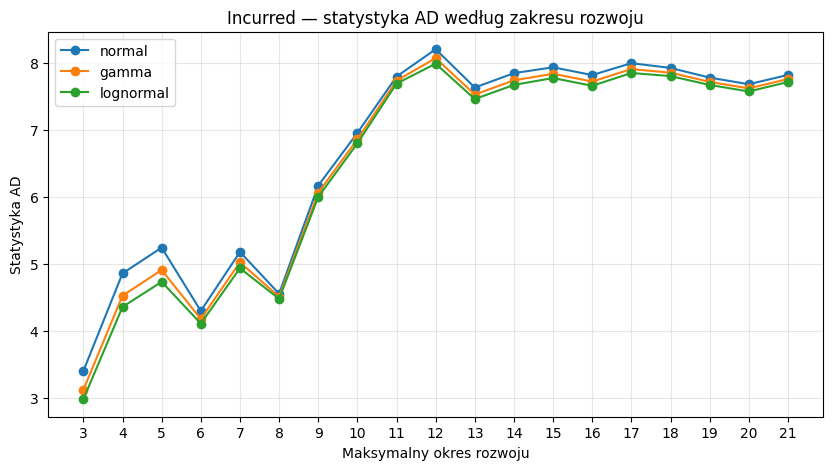

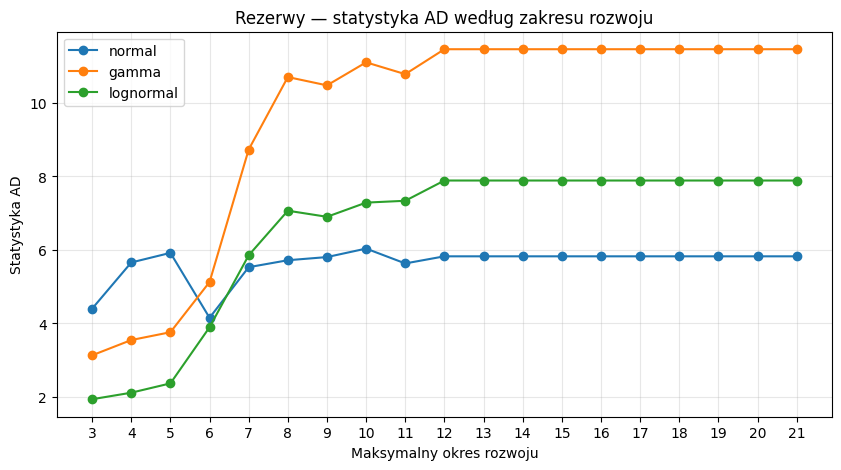

In [63]:

import matplotlib.pyplot as plt

for model in ["Incurred", "Rezerwy"]:

    dane = wyniki_zakresy[
        wyniki_zakresy["Model"] == model
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    for rozklad in ["normal", "gamma", "lognormal"]:

        d = dane[dane["Rozkład"] == rozklad]

        ax.plot(
            d["Max okres"],
            d["Statystyka testowa AD"],
            marker="o",
            label=rozklad
        )

    ax.set_title(
        f"{model} — statystyka AD według zakresu rozwoju"
    )
    ax.set_xlabel("Maksymalny okres rozwoju")
    ax.set_ylabel("Statystyka AD")
    ax.set_xticks(range(3, 22))
    ax.grid(alpha=0.3)
    ax.legend()

    plt.show()


In [66]:
# banchmark


import numpy as np
import pandas as pd
from scipy.stats import norm, gamma
from scipy.special import betaln


def benchmark_crps_paid_incurred(
    I, R, E_I, E_R,
    h, g, theta2_I, theta2_R,
    weights_inc,
    weights_R=None,
    max_okres=5
):
    """
    Niezależny benchmark CRPS:
    normalny, gamma, lognormalny.

    Osobno dla Incurred i rezerw.

    Nie zmienia parametrów istniejącego modelu.

    Zwraca
    -------
    tabela_globalna
    tabela_okresy
    tabela_obserwacje
    diagnostyka
    """

    I = np.asarray(I, dtype=float)
    R = np.asarray(R, dtype=float)
    E_I = np.asarray(E_I, dtype=float)
    E_R = np.asarray(E_R, dtype=float)

    h = np.asarray(h, dtype=float)
    g = np.asarray(g, dtype=float)
    theta2_I = np.asarray(theta2_I, dtype=float)
    theta2_R = np.asarray(theta2_R, dtype=float)

    W_I = np.asarray(weights_inc, dtype=float)

    W_R = (
        W_I.copy() if weights_R is None
        else np.asarray(weights_R, dtype=float)
    )

    a = I.shape[0]

    for name, M in [
        ("I", I), ("R", R),
        ("E_I", E_I), ("E_R", E_R)
    ]:
        if M.shape != (a, a):
            raise ValueError(f"Niepoprawny wymiar {name}.")

    for name, p in [
        ("h", h), ("g", g),
        ("theta2_I", theta2_I),
        ("theta2_R", theta2_R)
    ]:
        if p.shape != (a - 1,):
            raise ValueError(f"Niepoprawny wymiar {name}.")

    for name, W in [
        ("weights_inc", W_I),
        ("weights_R", W_R)
    ]:
        if W.shape != (a - 1, a - 1):
            raise ValueError(f"Niepoprawny wymiar {name}.")

        if not np.all(np.isin(W, [0, 1])):
            raise ValueError(f"Niepoprawne wagi {name}.")

    if not 1 <= max_okres <= a - 1:
        raise ValueError("Niepoprawny max_okres.")

    # -----------------------------------------
    # CRPS: rozkład normalny
    # -----------------------------------------

    def crps_normal(y, mu, var):

        sd = np.sqrt(var)
        z = (y - mu) / sd

        return sd * (
            z * (2 * norm.cdf(z) - 1)
            + 2 * norm.pdf(z)
            - 1 / np.sqrt(np.pi)
        )

    # -----------------------------------------
    # CRPS: rozkład gamma
    # -----------------------------------------

    def crps_gamma(y, mu, var):

        shape = mu**2 / var
        scale = var / mu

        F1 = gamma.cdf(y, a=shape, scale=scale)
        F2 = gamma.cdf(y, a=shape + 1, scale=scale)

        return (
            y * (2 * F1 - 1)
            - mu * (2 * F2 - 1)
            - scale * np.exp(-betaln(0.5, shape))
        )

    # -----------------------------------------
    # CRPS: rozkład lognormalny
    # -----------------------------------------

    def crps_lognormal(y, mu, var):

        s2 = np.log1p(var / mu**2)
        s = np.sqrt(s2)
        m = np.log(mu) - s2 / 2

        z = np.full_like(y, -np.inf, dtype=float)

        positive = y > 0

        z[positive] = (
            np.log(y[positive]) - m[positive]
        ) / s[positive]

        return (
            y * (2 * norm.cdf(z) - 1)
            - 2 * mu * (
                norm.cdf(z - s)
                + norm.cdf(s / np.sqrt(2))
                - 1
            )
        )

    # -----------------------------------------
    # Przygotowanie obserwacji
    # -----------------------------------------

    rows = []
    diag_rows = []

    konfiguracje = [
        ("Incurred", I, E_I, h, theta2_I, W_I),
        ("Rezerwy", R, E_R, g, theta2_R, W_R)
    ]

    for model, X, E, coef, theta2, W in konfiguracje:

        for j in range(max_okres):

            n_rows = a - j - 1

            selected = np.flatnonzero(
                W[:n_rows, j] == 1
            )

            e = E[selected, j]
            x0 = X[selected, j]
            y = X[selected, j + 1]

            if model == "Incurred":
                mu = x0 + coef[j] * e
            else:
                mu = coef[j] * e

            var = theta2[j] * e

            valid = (
                np.isfinite(e)
                & np.isfinite(x0)
                & np.isfinite(y)
                & np.isfinite(mu)
                & np.isfinite(var)
                & (e > 0)
                & (mu > 0)
                & (var > 0)
                & (y > 0)
            )

            diag_rows.append({
                "Model": model,
                "Okres": j + 1,
                "Wybrane wagami": len(selected),
                "Do benchmarku": int(np.sum(valid)),
                "Wyłączone": int(np.sum(~valid))
            })

            if not np.any(valid):
                continue

            y = y[valid]
            mu = mu[valid]
            var = var[valid]
            indeksy = selected[valid]

            sd = np.sqrt(var)

            scores = {
                "normal": crps_normal(y, mu, var),
                "gamma": crps_gamma(y, mu, var),
                "lognormal": crps_lognormal(y, mu, var)
            }

            for nazwa, crps in scores.items():

                for k in range(len(y)):

                    rows.append({
                        "Model": model,
                        "Okres": j + 1,
                        "Indeks roku": int(indeksy[k]),
                        "Rozkład": nazwa,
                        "Obserwacja": y[k],
                        "Średnia": mu[k],
                        "Wariancja": var[k],
                        "CRPS": crps[k],
                        "CRPS standaryzowany": (
                            crps[k] / sd[k]
                        )
                    })

    tabela_obserwacje = pd.DataFrame(rows)

    diagnostyka = pd.DataFrame(diag_rows)

    if tabela_obserwacje.empty:
        raise ValueError(
            "Brak obserwacji do benchmarku CRPS."
        )

    # -----------------------------------------
    # Globalne wyniki
    # -----------------------------------------

    tabela_globalna = (
        tabela_obserwacje
        .groupby(["Model", "Rozkład"])
        .agg(
            Liczebnosc=("CRPS", "size"),
            CRPS_sredni=("CRPS", "mean"),
            CRPS_standaryzowany=(
                "CRPS standaryzowany", "mean"
            ),
            CRPS_mediana=("CRPS", "median")
        )
        .reset_index()
    )

    tabela_globalna["Ranking CRPS"] = (
        tabela_globalna
        .groupby("Model")["CRPS_sredni"]
        .rank(method="min")
    )

    tabela_globalna["Ranking CRPS stand."] = (
        tabela_globalna
        .groupby("Model")["CRPS_standaryzowany"]
        .rank(method="min")
    )

    # -----------------------------------------
    # Wyniki według okresów
    # -----------------------------------------

    tabela_okresy = (
        tabela_obserwacje
        .groupby(["Model", "Okres", "Rozkład"])
        .agg(
            Liczebnosc=("CRPS", "size"),
            CRPS_sredni=("CRPS", "mean"),
            CRPS_standaryzowany=(
                "CRPS standaryzowany", "mean"
            )
        )
        .reset_index()
    )

    tabela_okresy["Ranking CRPS"] = (
        tabela_okresy
        .groupby(["Model", "Okres"])["CRPS_sredni"]
        .rank(method="min")
    )

    return (
        tabela_globalna,
        tabela_okresy,
        tabela_obserwacje,
        diagnostyka
    )



In [70]:
(
    crps_global,
    crps_okresy,
    crps_obserwacje,
    crps_diagnostyka
) = benchmark_crps_paid_incurred(
    I=I,
    R=R,
    E_I=E_I,
    E_R=E_R,
    h=h,
    g=g,
    theta2_I=theta2_I,
    theta2_R=theta2_R,
    weights_inc=weights_inc,
    max_okres=5
)


# ==========================================
# 1. WYNIKI GLOBALNE — POPRAWA WZGLĘDEM NORMALNEGO
# ==========================================

crps_global = crps_global.copy()

referencja_global = (
    crps_global[crps_global["Rozkład"] == "normal"]
    .set_index("Model")["CRPS_sredni"]
)

crps_global["CRPS_normalny"] = (
    crps_global["Model"].map(referencja_global)
)

crps_global["Poprawa_CRPS_%"] = (
    100 * (
        crps_global["CRPS_normalny"]
        - crps_global["CRPS_sredni"]
    ) / crps_global["CRPS_normalny"]
)


# ==========================================
# 2. WYNIKI WEDŁUG OKRESÓW — POPRAWA %
# ==========================================

crps_okresy = crps_okresy.copy()

referencja_okresy = (
    crps_okresy[crps_okresy["Rozkład"] == "normal"]
    .set_index(["Model", "Okres"])["CRPS_sredni"]
)

crps_okresy["CRPS_normalny"] = [
    referencja_okresy.loc[(model, okres)]
    for model, okres in zip(
        crps_okresy["Model"],
        crps_okresy["Okres"]
    )
]

crps_okresy["Poprawa_CRPS_%"] = (
    100 * (
        crps_okresy["CRPS_normalny"]
        - crps_okresy["CRPS_sredni"]
    ) / crps_okresy["CRPS_normalny"]
)


# ==========================================
# 3. WYŚWIETLENIE
# ==========================================

print("CRPS — WYNIKI GLOBALNE")
display(crps_global.round(6))

print("\nCRPS — WEDŁUG OKRESÓW")
display(crps_okresy.round(6))

print("\nDIAGNOSTYKA")
display(crps_diagnostyka)

CRPS — WYNIKI GLOBALNE


,Model,Rozkład,Liczebnosc,CRPS_sredni,CRPS_standaryzowany,CRPS_mediana,Ranking CRPS,Ranking CRPS stand.,CRPS_normalny,Poprawa_CRPS_%
0,Incurred,gamma,93,4.868043e+06,0.499700,2.665538e+06,2.0,2.0,4.886748e+06,0.382778
1,Incurred,lognormal,93,4.858276e+06,0.498849,2.678502e+06,1.0,1.0,4.886748e+06,0.582631
2,Incurred,normal,93,4.886748e+06,0.501278,2.717971e+06,3.0,3.0,4.886748e+06,0.000000
3,Rezerwy,gamma,90,3.653873e+06,0.470504,1.727580e+06,2.0,2.0,3.849940e+06,5.092727
4,Rezerwy,lognormal,90,3.585735e+06,0.456023,1.681064e+06,1.0,1.0,3.849940e+06,6.862571
5,Rezerwy,normal,90,3.849940e+06,0.497763,2.094463e+06,3.0,3.0,3.849940e+06,0.000000



CRPS — WEDŁUG OKRESÓW


,Model,Okres,Rozkład,Liczebnosc,CRPS_sredni,CRPS_standaryzowany,Ranking CRPS,CRPS_normalny,Poprawa_CRPS_%
0,Incurred,1,gamma,20,1.011715e+07,0.522944,2.0,1.016005e+07,0.422289
1,Incurred,1,lognormal,20,1.009551e+07,0.521631,1.0,1.016005e+07,0.635235
2,Incurred,1,normal,20,1.016005e+07,0.525427,3.0,1.016005e+07,0.000000
3,Incurred,2,gamma,19,4.717650e+06,0.535922,2.0,4.722514e+06,0.102996
4,Incurred,2,lognormal,19,4.715173e+06,0.535617,1.0,4.722514e+06,0.155433
5,Incurred,2,normal,19,4.722514e+06,0.536471,3.0,4.722514e+06,0.000000
6,Incurred,3,gamma,19,5.110915e+06,0.435403,2.0,5.149091e+06,0.741416
7,Incurred,3,lognormal,19,5.090069e+06,0.433474,1.0,5.149091e+06,1.146264
8,Incurred,3,normal,19,5.149091e+06,0.438897,3.0,5.149091e+06,0.000000
9,Incurred,4,gamma,18,1.510417e+06,0.474925,2.0,1.512597e+06,0.144067



DIAGNOSTYKA


,Model,Okres,Wybrane wagami,Do benchmarku,Wyłączone
0,Incurred,1,20,20,0
1,Incurred,2,19,19,0
2,Incurred,3,19,19,0
3,Incurred,4,18,18,0
4,Incurred,5,17,17,0
5,Rezerwy,1,20,20,0
6,Rezerwy,2,19,19,0
7,Rezerwy,3,19,19,0
8,Rezerwy,4,18,17,1
9,Rezerwy,5,17,15,2
